# Linear Regression

## Question

Is anime with more ratings generally scored more highly?

## Aim

The aim of this notebook is to use linear regression to investigate the relationship between the number of ratings an anime receives (`scored_by`) and its average score (`score`).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## 1. Load the data

I will use anime that have both a score and a number of ratings.

In [3]:
df = pd.read_csv("../data/cleaned_popular_anime.csv")

model_data = df[["scored_by", "score"]].dropna().copy()
model_data = model_data[model_data["scored_by"] > 0]
model_data["log_scored_by"] = np.log1p(model_data["scored_by"])

print("Rows used:", len(model_data))
model_data.head()

Rows used: 18541


,scored_by,score,log_scored_by
0,676737.0,9.30,13.425039
1,2223666.0,9.10,14.614668
2,1467570.0,9.07,14.199119
3,1700946.0,9.05,14.346696
4,264260.0,9.05,12.484693


## 2. Look at the relationship

This scatter plot shows anime scores against the number of ratings. The x-axis uses a log scale to make the values easier to compare.

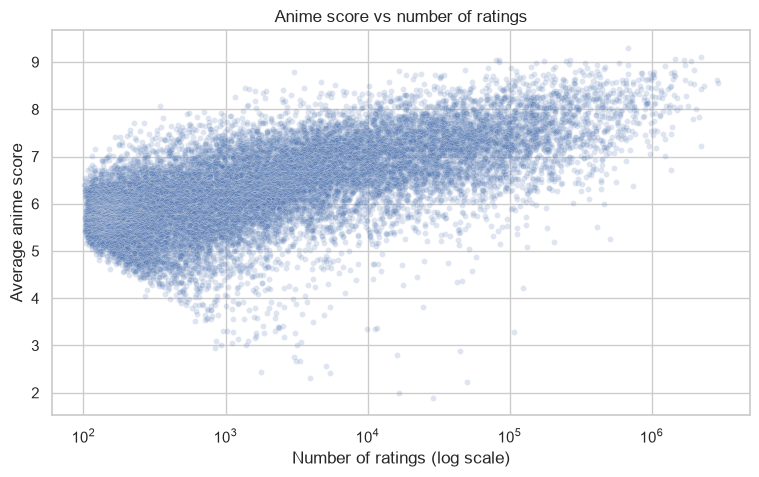

Correlation: 0.668


In [4]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=model_data, x="scored_by", y="score", alpha=0.18, s=18)
plt.xscale("log")
plt.xlabel("Number of ratings (log scale)")
plt.ylabel("Average anime score")
plt.title("Anime score vs number of ratings")
plt.show()

print("Correlation:", round(model_data["log_scored_by"].corr(model_data["score"]), 3))

## 3. Train the model

I will use 80% of the data to train the model and 20% to test it.

In [5]:
X = model_data[["log_scored_by"]]
y = model_data["score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 3))
print("Coefficient:", round(model.coef_[0], 3))

Intercept: 4.316
Coefficient: 0.27


## 4. Plot the regression line

The line shows the score predicted by the model for different rating counts. The points are the actual anime scores.

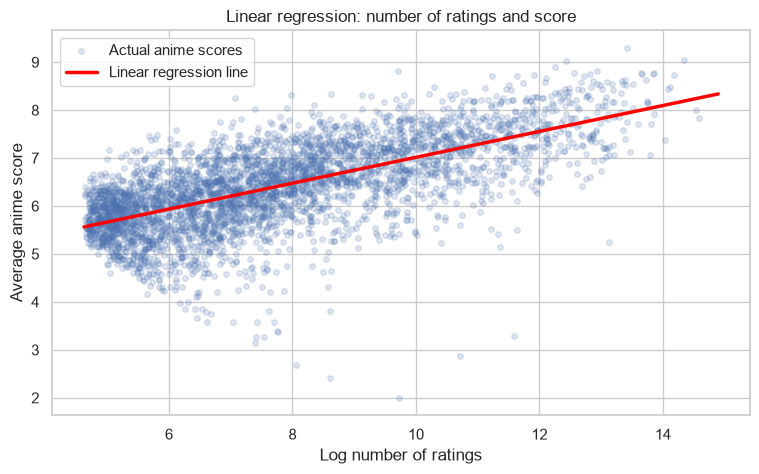

In [6]:
plot_sample = model_data.sample(min(4000, len(model_data)), random_state=42)

x_line = np.linspace(model_data["log_scored_by"].min(),
                     model_data["log_scored_by"].max(), 200)
y_line = model.predict(pd.DataFrame({"log_scored_by": x_line}))

plt.figure(figsize=(9, 5))
plt.scatter(plot_sample["log_scored_by"], plot_sample["score"],
            alpha=0.18, s=16, label="Actual anime scores")
plt.plot(x_line, y_line, color="red", linewidth=2.5,
         label="Linear regression line")
plt.xlabel("Log number of ratings")
plt.ylabel("Average anime score")
plt.title("Linear regression: number of ratings and score")
plt.legend()
plt.show()

## 5. Make predictions

I will compare the model's predictions with the actual scores in the test data.

In [7]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual score": y_test,
    "Predicted score": y_pred
})
results.head(10)

,Actual score,Predicted score
12382,5.98,5.645874
2281,7.45,7.087307
14905,5.63,6.174871
15933,5.45,5.773017
15778,5.48,7.011002
16827,5.27,5.771793
17389,5.10,5.835939
8686,6.44,6.046256
14611,5.67,6.190150
12777,5.93,6.289715


## 6. Evaluate the model

I will compare linear regression with a simple baseline that always predicts the average training score.

In [8]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

metrics = pd.DataFrame({
    "Model": ["Linear regression", "Mean baseline"],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, baseline_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, baseline_pred))
    ],
    "R-squared": [
        r2_score(y_test, y_pred),
        r2_score(y_test, baseline_pred)
    ]
})

metrics.round(3)

,Model,MAE,RMSE,R-squared
0,Linear regression,0.494,0.652,0.457
1,Mean baseline,0.705,0.884,-0.000


## 7. Actual scores vs predicted scores

Points close to the dashed line are more accurate predictions.

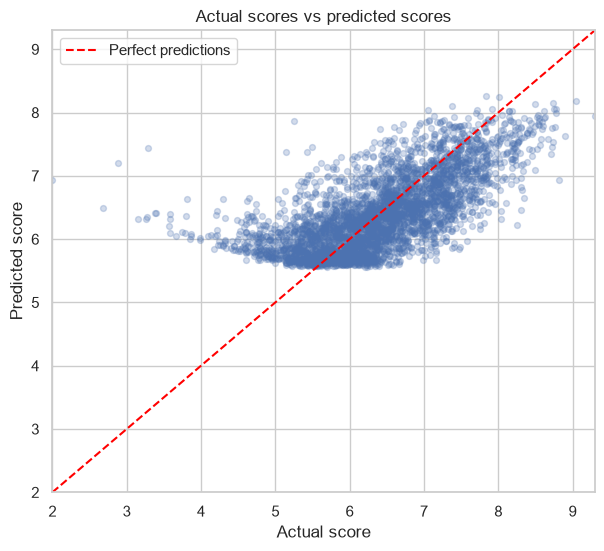

In [9]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.25, s=18)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limits, limits, "--", color="red", label="Perfect predictions")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Actual score")
plt.ylabel("Predicted score")
plt.title("Actual scores vs predicted scores")
plt.legend()
plt.show()

## 8. Residuals

Residuals are the differences between the actual scores and the predicted scores. A residual close to zero means the prediction was closer to the actual score.

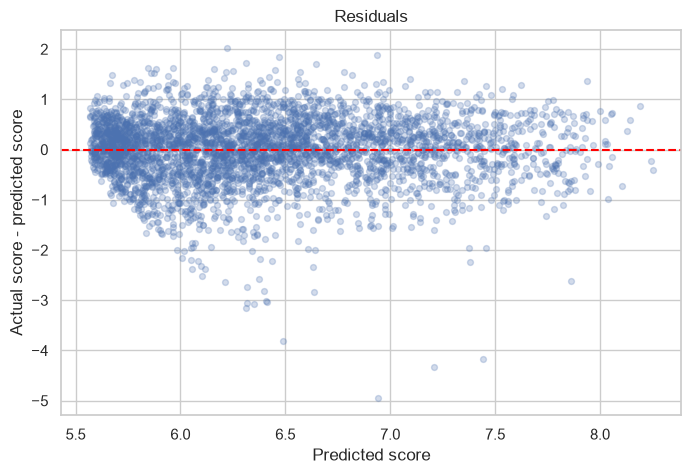

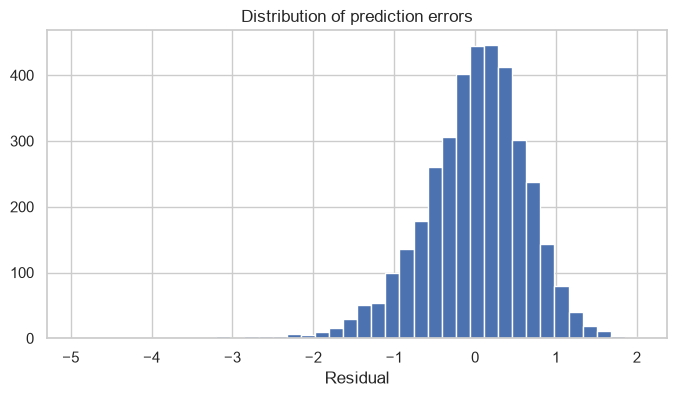

In [10]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.25, s=18)
plt.axhline(0, linestyle="--", color="red")
plt.xlabel("Predicted score")
plt.ylabel("Actual score - predicted score")
plt.title("Residuals")
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=40, edgecolor="white")
plt.xlabel("Residual")
plt.title("Distribution of prediction errors")
plt.show()

## Conclusion

There is a positive relationship between the number of ratings and an anime's score, but the results are quite spread out.

Linear regression showed this relationship, but wasn't very accurate at predicting scores.

Other factors, such as genre, type and release year, could be tested to see if they improve the predictions.